# Module 3 - Classification

## Churn Prediction Project

### Problem overview

**Churn** - whether a customer will leave our company or cancel their contract/subscription.

The goal is to assign a score to each customer that represents the likelihood that they will churn, so that we can do something now to prevent it (e.g. send them a promo/discount).

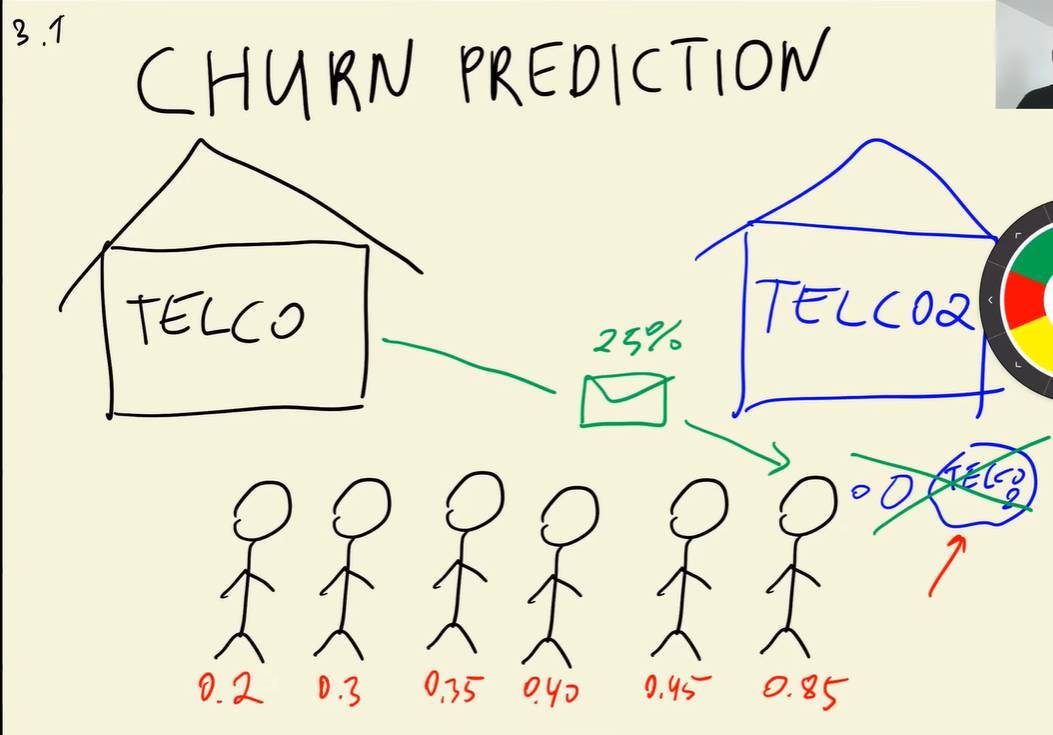

**We should be careful:**

- We don’t want to unintentionally send promos/discounts to loyal customers who are unlikely to churn (that would mean losing money)
- We also don’t want to miss customers that have a high chance of churning (also lose money)

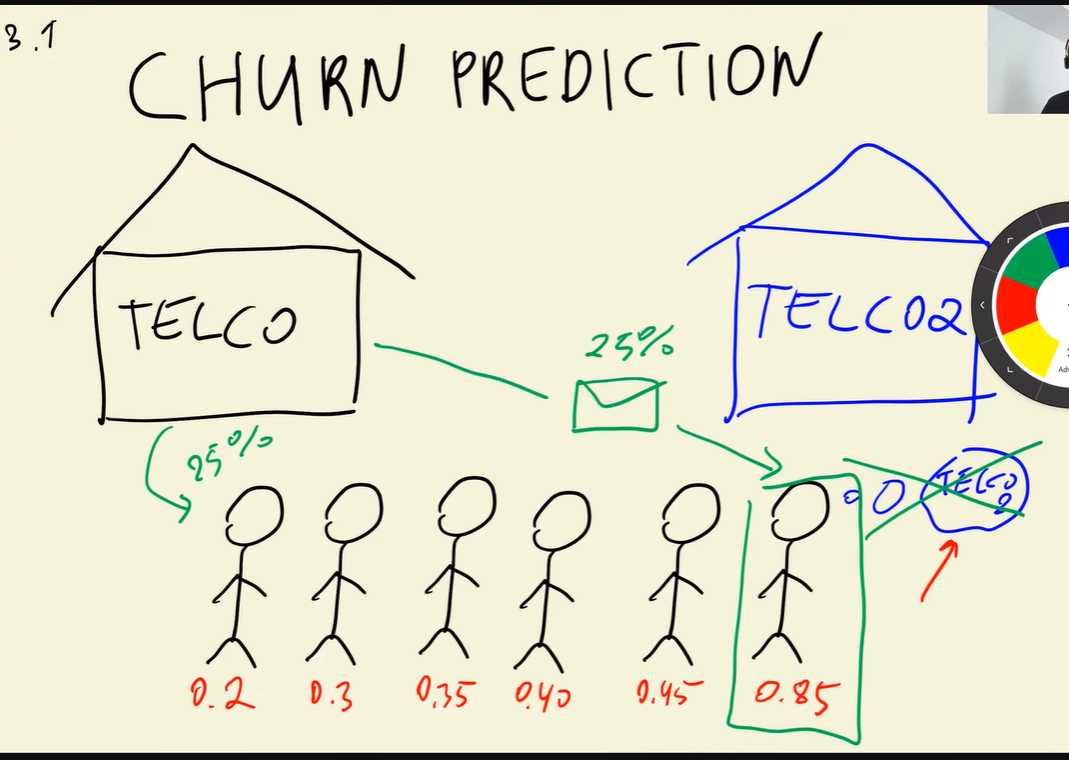

### Translating the problem into ML task

**Binary Classification**

From the name itself (binary), we are trying to predict whether something (e.g. customer, email) is one of two values:

- 1 (positive/true): churned, spam
- 0 (negative/false): not churned, not spam

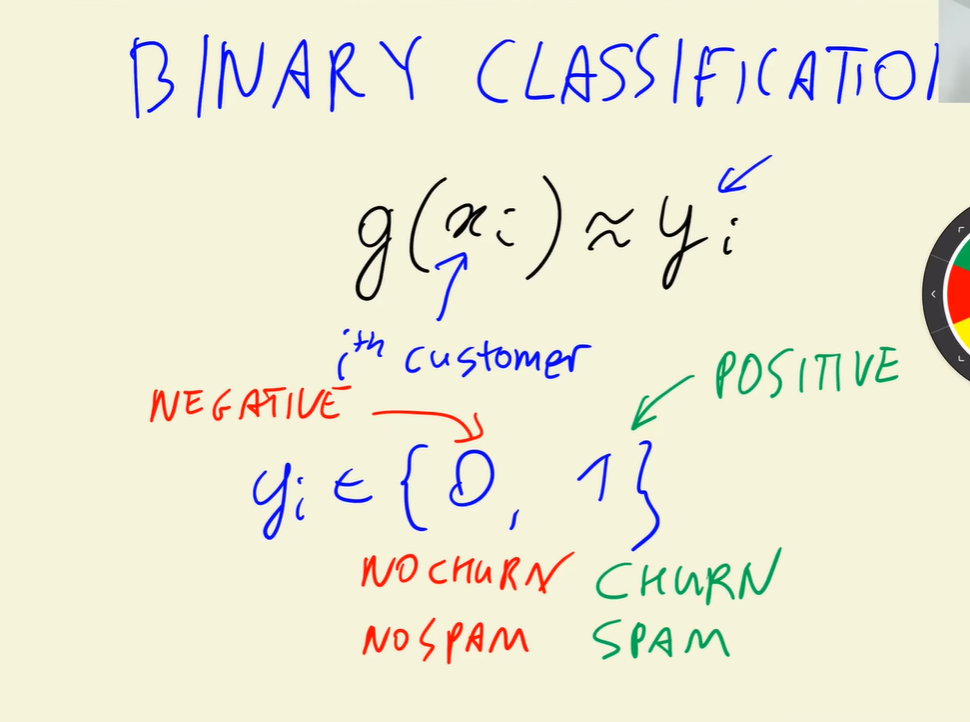

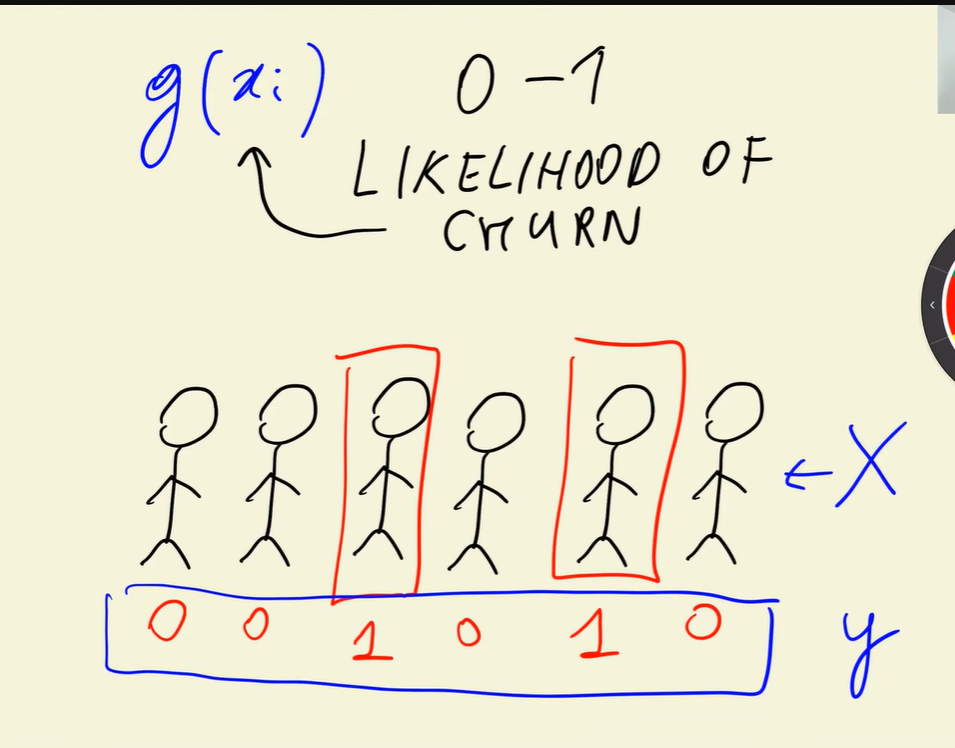

`X` represents the attributes of our customers

`y` represents the label (churned / not churned)

## Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint

np.set_printoptions(suppress=True)

RANDOM_SEED = 1

### Get the dataset

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

# -nc means "no clobber": wget skips the download if the file already exists
!wget -nc -O churn_data.csv $data

File ‘churn_data.csv’ already there; not retrieving.


In [3]:
df = pd.read_csv('churn_data.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Another way to preview a dataframe
# personally, don't really like this view
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


### Make everything uniform

In [5]:
# Make column names consistent
df.columns = df.columns.str.lower().str.replace(' ', '_')

# Make categorical values consistent
categorical_columns = list(df.dtypes[df.dtypes == 'string'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.head()


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,yes


### Data types

In [6]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

You would expect totalchargers to be numeric, but here it's a `str`

When we try to convert it to a numeric col, we get an error

This is because the col has non-numeric values (e.g. `_`)

This is a sign that **this column actually has hidden missing values**

In [7]:
# pd.to_numeric(df['totalcharges'])

In [8]:
# If there are values that would cause errors (non-numeric chars), replace them with nulls
totalcharges = pd.to_numeric(df['totalcharges'], errors='coerce')

totalcharges.isnull().sum()

np.int64(11)

This means the `totalcharges` column has 11 missing values that we need to handle

### Missing values

In [9]:
df.loc[totalcharges.isnull()]

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
488,4472-lvygi,female,0,yes,yes,0,no,no_phone_service,dsl,yes,...,yes,yes,yes,no,two_year,yes,bank_transfer_(automatic),52.55,_,no
753,3115-czmzd,male,0,no,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,20.25,_,no
936,5709-lvoeq,female,0,yes,yes,0,yes,no,dsl,yes,...,yes,no,yes,yes,two_year,no,mailed_check,80.85,_,no
1082,4367-nuyao,male,0,yes,yes,0,yes,yes,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,25.75,_,no
1340,1371-dwpaz,female,0,yes,yes,0,no,no_phone_service,dsl,yes,...,yes,yes,yes,no,two_year,no,credit_card_(automatic),56.05,_,no
3331,7644-omvmy,male,0,yes,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.85,_,no
3826,3213-vvolg,male,0,yes,yes,0,yes,yes,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,25.35,_,no
4380,2520-sgtta,female,0,yes,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,20.00,_,no
5218,2923-arzlg,male,0,yes,yes,0,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,one_year,yes,mailed_check,19.70,_,no
6670,4075-wkniu,female,0,yes,yes,0,yes,yes,dsl,no,...,yes,yes,yes,no,two_year,no,mailed_check,73.35,_,no


In [10]:
df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce')
df['totalcharges'] = df['totalcharges'].fillna(0)

print(f'Missing values: {df['totalcharges'].isnull().sum()}')
print(f'Data type: {df['totalcharges'].dtype}')

Missing values: 0
Data type: float64


### Convert target values to numeric

In [11]:
df['churn'].unique()

<StringArray>
['no', 'yes']
Length: 2, dtype: str

In [12]:
df['churn'] = (df['churn'] == 'yes').astype('int')

df['churn'].unique()

array([0, 1])

## Setup Validation Framework

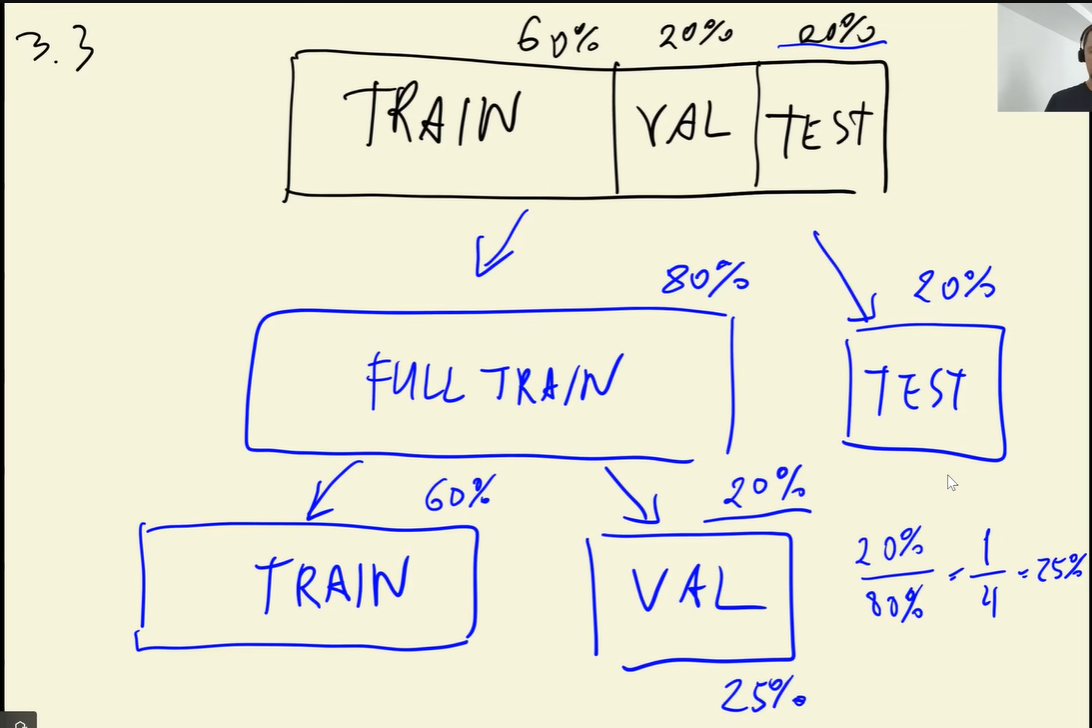

### First split: Full train & test

In [13]:
from sklearn.model_selection import train_test_split

# 1st split: combined train+val, test
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=RANDOM_SEED)

print(f'Train+Val: {df_full_train.shape}')
print(f'Test: {df_test.shape}')


Train+Val: (5634, 21)
Test: (1409, 21)


### Second split: train & validation

In [14]:
# 2nd split: train, val
# We should not use 20% here
# We need to compute the 20% compared to the full dataset, not the full train set
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=RANDOM_SEED)

print(f'Train: {df_train.shape}')
print(f'Val: {df_val.shape}')

Train: (4225, 21)
Val: (1409, 21)


### Check partitions

In [15]:
print(f'Train size: {len(df_train)}')
print(f'Val size: {len(df_val)}')
print(f'Test size: {len(df_test)}')

Train size: 4225
Val size: 1409
Test size: 1409


### Reset indexes

In [16]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### Split features and target

In [17]:
y_train = df_train['churn']
y_train.head()


0    0
1    0
2    1
3    0
4    0
Name: churn, dtype: int64

In [18]:
y_val = df_val['churn']
y_val.head()

0    0
1    0
2    0
3    1
4    0
Name: churn, dtype: int64

In [19]:
y_test = df_test['churn']
y_test.head()

0    0
1    0
2    0
3    1
4    0
Name: churn, dtype: int64

In [20]:
del df_train['churn']

df_train.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
0,8015-ihcgw,female,0,yes,yes,72,yes,yes,fiber_optic,yes,yes,yes,yes,yes,yes,two_year,yes,electronic_check,115.50,8425.15
1,1960-uycnn,male,0,no,no,10,yes,yes,fiber_optic,no,yes,yes,no,no,yes,month-to-month,yes,electronic_check,95.25,1021.55
2,9250-wypll,female,0,no,no,5,yes,yes,fiber_optic,no,no,no,no,no,no,month-to-month,no,electronic_check,75.55,413.65
3,6786-obwqr,female,0,yes,yes,5,yes,no,fiber_optic,no,no,no,no,yes,no,month-to-month,yes,electronic_check,80.85,356.10
4,1328-euzhc,female,0,yes,no,18,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,20.10,370.50


In [21]:
del df_val['churn']

df_val.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
0,5846-neqvz,male,0,yes,yes,71,yes,no,dsl,yes,no,yes,yes,no,yes,two_year,yes,credit_card_(automatic),70.85,4973.40
1,3645-deygf,male,0,no,yes,1,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,no,mailed_check,20.75,20.75
2,3590-tcxtb,male,0,no,no,1,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,no,mailed_check,20.35,20.35
3,8433-wxgna,male,0,no,no,2,yes,no,fiber_optic,yes,no,no,no,no,no,month-to-month,yes,electronic_check,75.70,189.20
4,2654-vbvpb,female,0,no,no,1,yes,no,no,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,no_internet_service,month-to-month,no,bank_transfer_(automatic),19.90,19.90


In [22]:
del df_test['churn']

df_test.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges
0,8879-zkjof,female,0,no,no,41,yes,no,dsl,yes,no,yes,yes,yes,yes,one_year,yes,bank_transfer_(automatic),79.85,3320.75
1,0201-mibol,female,1,no,no,66,yes,yes,fiber_optic,yes,no,no,no,yes,yes,two_year,yes,bank_transfer_(automatic),102.40,6471.85
2,1600-dilpe,female,0,no,no,12,yes,no,dsl,no,no,no,no,no,no,month-to-month,yes,bank_transfer_(automatic),45.00,524.35
3,8601-qacrs,female,0,no,no,5,yes,yes,dsl,no,no,no,no,no,no,month-to-month,yes,mailed_check,50.60,249.95
4,7919-zodzz,female,0,yes,yes,10,yes,no,dsl,no,yes,yes,no,no,yes,one_year,yes,mailed_check,65.90,660.05


## EDA

- Check missing values
- Look at the target variable (churn)
- Look at numerical and categorical columns

In [23]:
df_full_train = df_full_train.reset_index(drop=True)

df_full_train.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
1,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
2,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
3,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
4,2364-ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0


### Missing values

In [24]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

### Check distribution of the target variable

Look at the counts of the target labels

In [25]:
df_full_train['churn'].value_counts()

churn
0    4113
1    1521
Name: count, dtype: int64

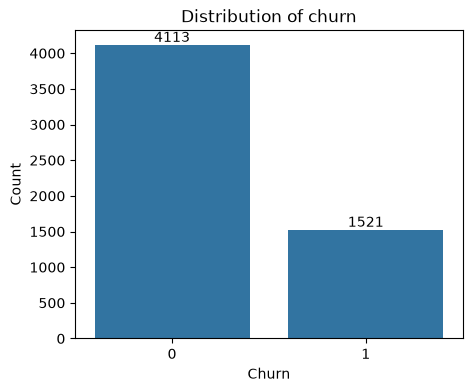

In [26]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_full_train, x='churn')
ax.bar_label(ax.containers[0])  # show the count on top of each bar
plt.title('Distribution of churn')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

Look at the distribution in percentages

In [27]:
df_full_train['churn'].value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

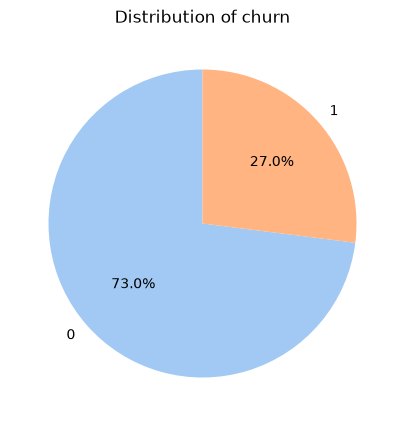

In [28]:
churn_pct = df_full_train['churn'].value_counts(normalize=True)

plt.figure(figsize=(5, 5))
plt.pie(
    churn_pct,
    labels=churn_pct.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('pastel')[:len(churn_pct)],
)
plt.title('Distribution of churn')
plt.show()


Based on this, our churn rate is around **27%**

In [29]:
# Another way to compute churn rate
global_churn_rate = df_full_train['churn'].mean()

global_churn_rate.round(4)

np.float64(0.27)

This is the explanation why we can compute churn rate using the mean

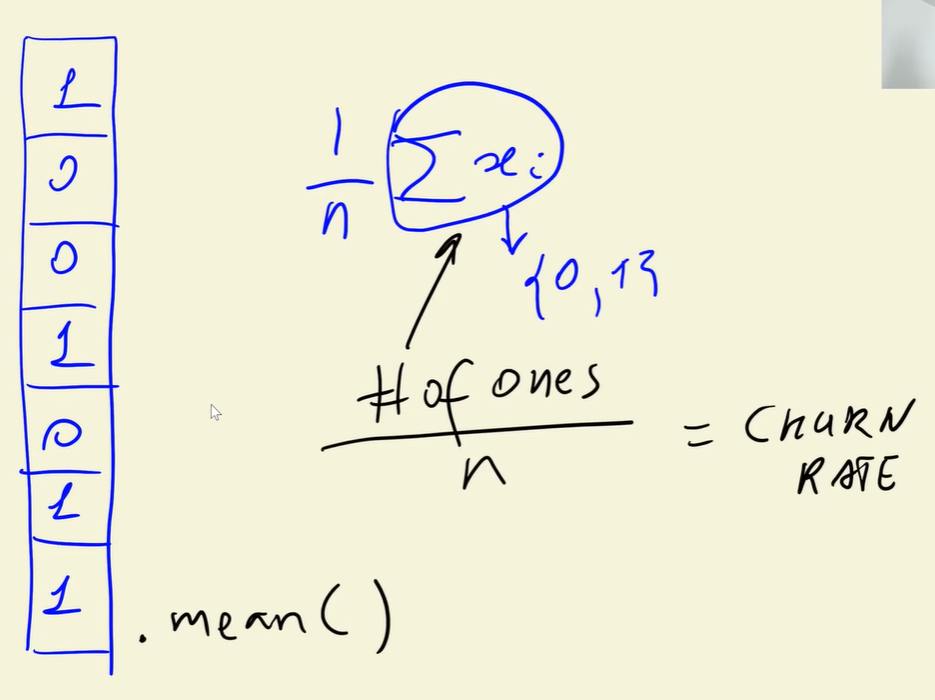

### Analyze churn against the features

In [30]:
numerical_features = ['tenure', 'monthlycharges', 'totalcharges']

numerical_features


['tenure', 'monthlycharges', 'totalcharges']

In [31]:
categorical_features = [
    col for col in df_full_train.columns 
    if col not in numerical_features + ['customerid', 'churn']
]

categorical_features

['gender',
 'seniorcitizen',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod']

In [32]:
df_full_train[categorical_features].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

## Feature Importance - Analyzing Churn Rate by Groups

**Feature Importance Analysis** - A part of EDA where we identify which features affect our target variable

- Churn rate
- Risk ratio
- Mutual information

### Difference

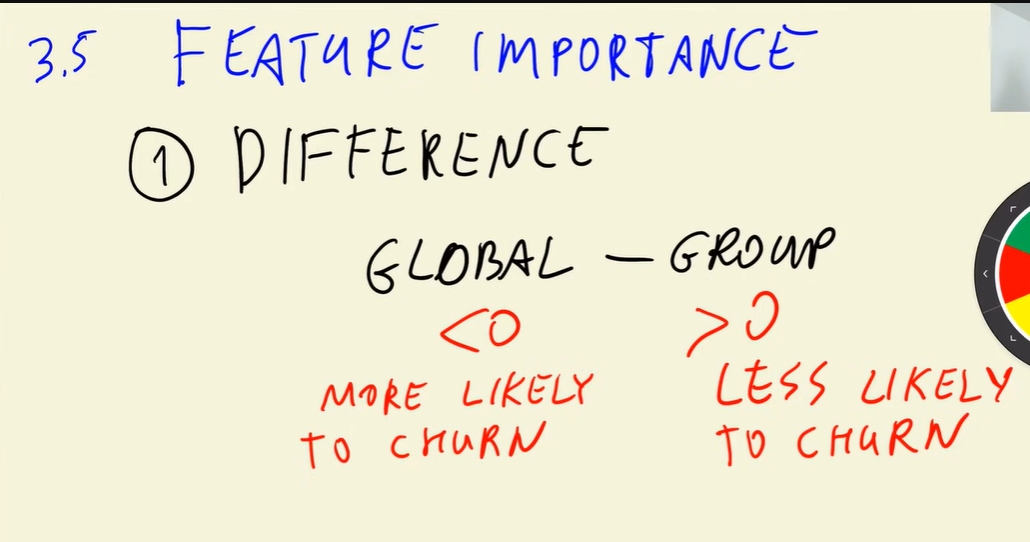

Comparing churn rate across genders

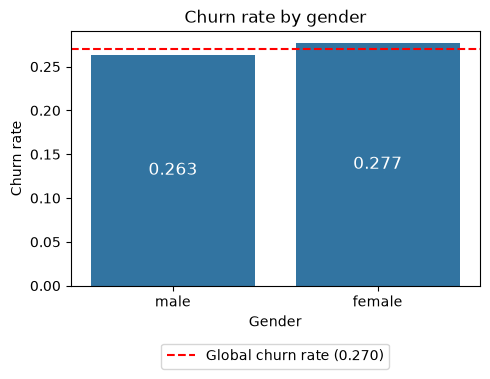

In [33]:
plt.figure(figsize=(5, 4))
ax = sns.barplot(data=df_full_train, x='gender', y='churn', errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.3f', label_type='center', color='white', fontsize=12)  # label inside the bar

ax.axhline(global_churn_rate, color='red', linestyle='--', label=f'Global churn rate ({global_churn_rate:.3f})')

plt.title('Churn rate by gender')
plt.xlabel('Gender')
plt.ylabel('Churn rate')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))  # move legend below the plot
plt.tight_layout()
plt.show()


Comparing churn rate by partner

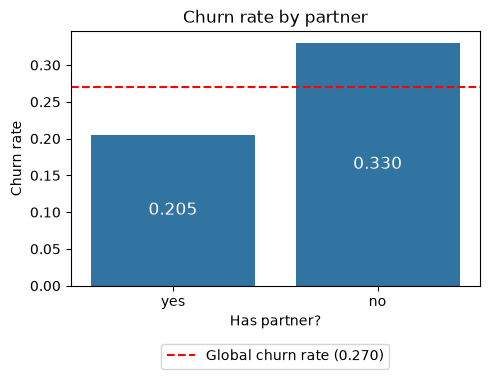

In [34]:
plt.figure(figsize=(5, 4))
ax = sns.barplot(data=df_full_train, x='partner', y='churn', errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.3f', label_type='center', color='white', fontsize=12)  # label inside the bar

ax.axhline(global_churn_rate, color='red', linestyle='--', label=f'Global churn rate ({global_churn_rate:.3f})')

plt.title('Churn rate by partner')
plt.xlabel('Has partner?')
plt.ylabel('Churn rate')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))  # move legend below the plot
plt.tight_layout()
plt.show()


### Risk Ratio

Difference and ratio tell us the same information, but in a different perspective:

- Differences tell us in absolute terms
- Ratios tell us in relative terms

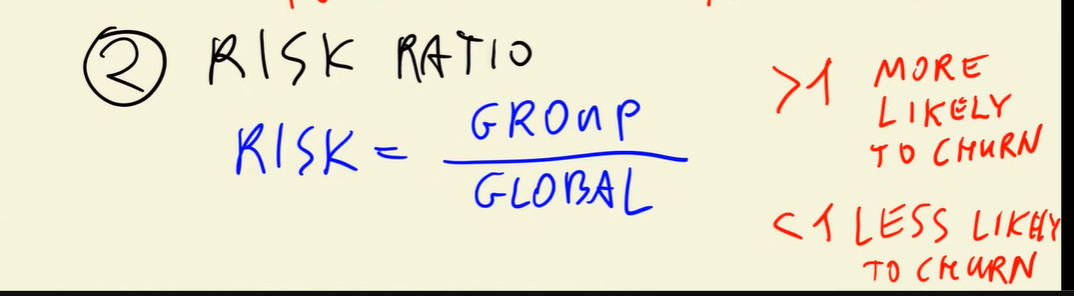

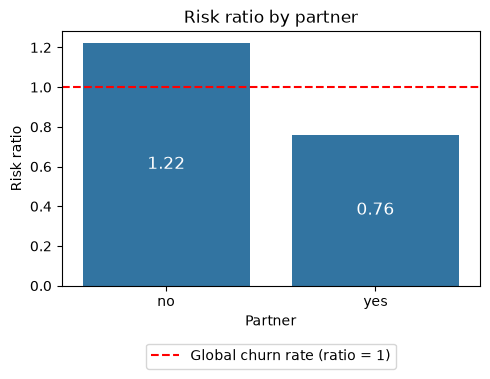

In [35]:
partner_risk = (
    df_full_train.groupby('partner')['churn'].mean() / global_churn_rate
).rename('risk_ratio').reset_index()

plt.figure(figsize=(5, 4))
ax = sns.barplot(data=partner_risk, x='partner', y='risk_ratio', order=['no', 'yes'])
ax.bar_label(ax.containers[0], fmt='%.2f', label_type='center', color='white', fontsize=12)
ax.axhline(1, color='red', linestyle='--', label='Global churn rate (ratio = 1)')

plt.title('Risk ratio by partner')
plt.xlabel('Partner')
plt.ylabel('Risk ratio')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()


How to read:

- Customers without a partner churn at a rate **22% higher** than the average customer
- Customers with a partner churn at a rate **24% lower** than the average customer

### Visualizing risk ratio

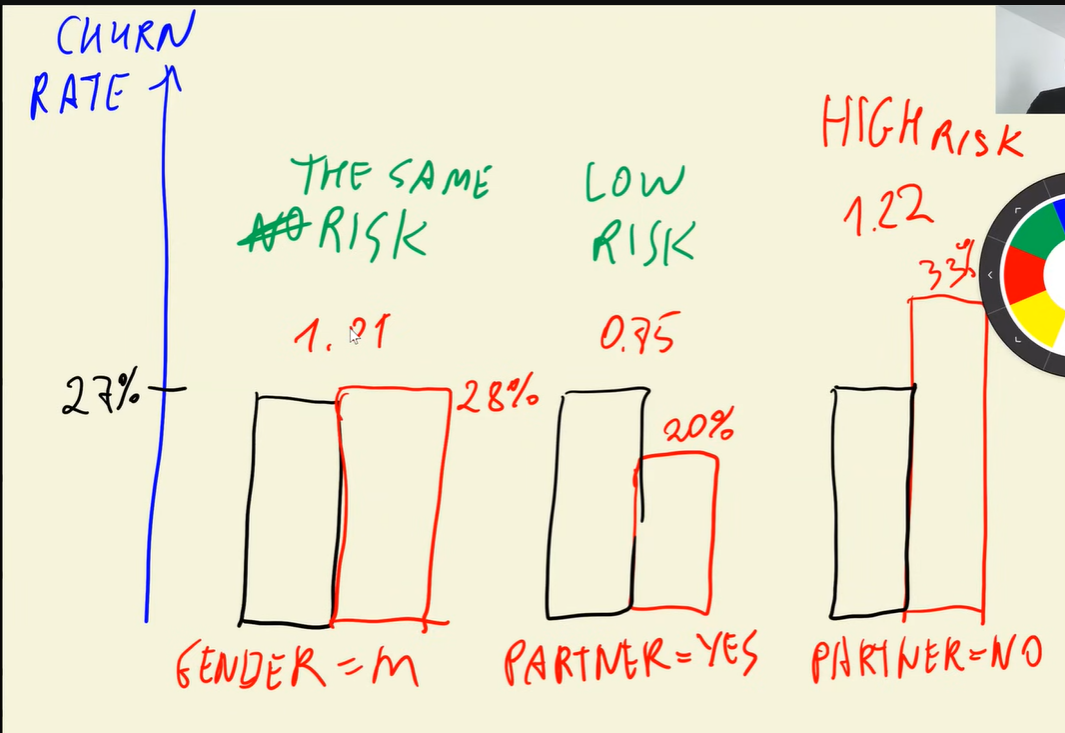

Legend:
- Black box: global average
- Red box: group average

### Calculate churn rate by different groups all at once

In [36]:
from IPython.display import display

for categorical in categorical_features:

    df_group = df_full_train.groupby(categorical)['churn'].agg(['mean', 'count'])

    df_group['diff'] = df_group['mean'] - global_churn_rate
    df_group['risk'] = df_group['mean'] / global_churn_rate

    display(df_group.round(4))
    print()

,mean,count,diff,risk
gender,,,,
female,0.2768,2796,0.0069,1.0254
male,0.2632,2838,-0.0068,0.9750


,mean,count,diff,risk
seniorcitizen,,,,
0,0.2423,4722,-0.0277,0.8974
1,0.4134,912,0.1434,1.5312


,mean,count,diff,risk
partner,,,,
no,0.3298,2932,0.0598,1.2217
yes,0.2050,2702,-0.0649,0.7595


,mean,count,diff,risk
dependents,,,,
no,0.3138,3968,0.0438,1.1622
yes,0.1657,1666,-0.1043,0.6137


,mean,count,diff,risk
phoneservice,,,,
no,0.2413,547,-0.0287,0.8939
yes,0.2730,5087,0.0031,1.0114


...

,mean,count,diff,risk
streamingtv,,,,
no,0.3428,2246,0.0729,1.2699
no_internet_service,0.0778,1221,-0.1922,0.2882
yes,0.3027,2167,0.0328,1.1213


,mean,count,diff,risk
streamingmovies,,,,
no,0.3389,2213,0.0689,1.2554
no_internet_service,0.0778,1221,-0.1922,0.2882
yes,0.3073,2200,0.0373,1.1382


,mean,count,diff,risk
contract,,,,
month-to-month,0.4317,3104,0.1617,1.5991
one_year,0.1206,1186,-0.1494,0.4466
two_year,0.0283,1344,-0.2417,0.1047


,mean,count,diff,risk
paperlessbilling,,,,
no,0.1721,2313,-0.0979,0.6374
yes,0.3382,3321,0.0682,1.2526


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.1682,1219,-0.1018,0.6229
credit_card_(automatic),0.1643,1217,-0.1056,0.6087
electronic_check,0.4559,1893,0.1859,1.6887
mailed_check,0.1939,1305,-0.0761,0.7181


## Feature Importance - Mutual Information

Mutual information is a concept from
[information theory](https://en.wikipedia.org/wiki/Mutual_information).
It tells us how much we can learn about one variable if we know the
value of another.

Practically, this helps us understand **whether a categorical feature is more important than other categorical features**, especially for predicting the target variable.

This helps us answer the question: *"How much do we learn about churn, by learning about the contract types?"*

In [37]:
from sklearn.metrics import mutual_info_score

mutual_info_score(df_full_train['churn'], df_full_train['contract'])

0.0983203874041556

Now, how about gender?

In [38]:
mutual_info_score(df_full_train['churn'], df_full_train['gender'])

0.0001174846211139946

To know which features are more informative, we compare their mutual info scores.

Contract has a higher mutual info score than gender (≈ 0.098 vs ≈ 0.0001). So, contract is a better predictor of churn than gender.

Practically, this means that if we know the contract type of a customer (e.g. they're on a month-to-month contract), it tells us more about whether they'll churn, compared to if we know their gender.


Now, let's find the mutual info score for all categorical features against the target:

In [39]:
def mutual_info_score_churn(feature):
    return mutual_info_score(feature, df_full_train['churn'])

df_full_train[categorical_features] \
    .apply(mutual_info_score_churn) \
    .sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

Knowing which categorical features are important matters because the model learns the patterns from these features to make predictions. If it learns patterns from important features, it can predict better. Conversely, if it learns patterns from irrelevant features, it may predict worse on new data.


## Feature Importance - Correlation

If we used group analysis and mutual information to determine the importance of categorical features to the target, for numerical features, we can use **pearson correlation**.

Correlation measures the dependency of the target (dependendent) variable to a numerical (independent) variable.

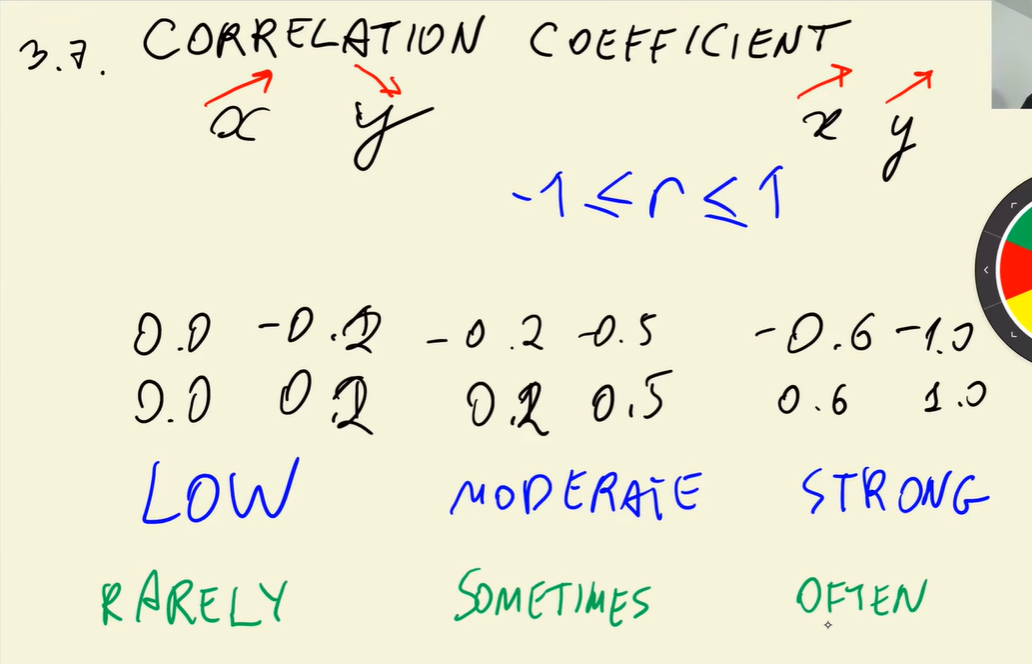

Apply the concepts to our data

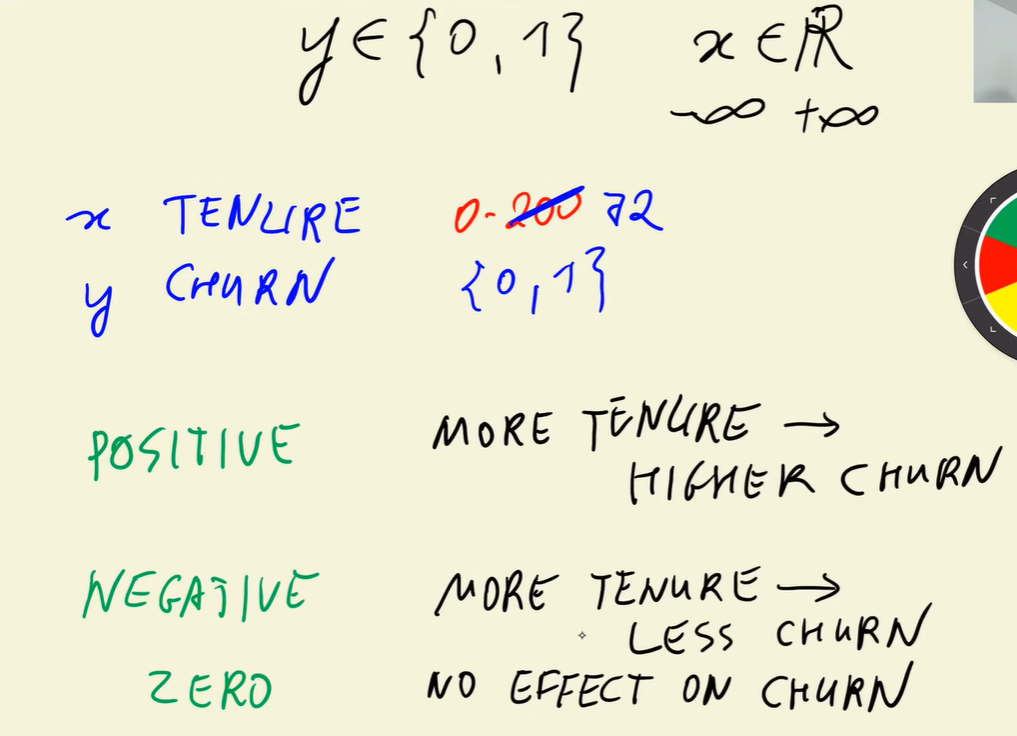

Implement in code

In [40]:
df_full_train[numerical_features].head()

,tenure,monthlycharges,totalcharges
0,12,19.70,258.35
1,42,73.90,3160.55
2,71,65.15,4681.75
3,71,85.45,6300.85
4,30,70.40,2044.75


In [41]:
df_full_train[numerical_features].corrwith(df_full_train['churn']).round(4)

tenure           -0.3519
monthlycharges    0.1968
totalcharges     -0.1964
dtype: float64

**Interpretation:**

- *Tenure* has a negative correlation with churn: the longer a customer has stayed, the less likely they are to leave.

- *Monthly charges* has a positive correlation with churn: customers who pay more each month are more likely to leave.

- *Total charges* has a negative correlation with churn: this seems counterintuitive, but total charges grows with tenure, so it mostly reflects long-time customers, who are less likely to leave.

Now, let's visualize the relationship between tenure and churn rate

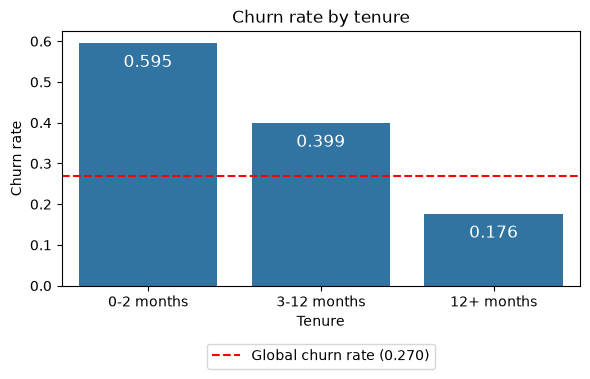

In [42]:
tenure_group = pd.cut(
    df_full_train['tenure'],
    bins=[-1, 2, 12, float('inf')],  # (-1, 2], (2, 12], (12, inf]
    labels=['0-2 months', '3-12 months', '12+ months'],
)

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=tenure_group, y=df_full_train['churn'], errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.3f', label_type='edge', padding=-20, color='white', fontsize=12)
ax.axhline(global_churn_rate, color='red', linestyle='--', label=f'Global churn rate ({global_churn_rate:.3f})')

plt.title('Churn rate by tenure')
plt.xlabel('Tenure')
plt.ylabel('Churn rate')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()


**Insight:** Churn rate drops sharply as tenure grows: about 60% of customers in their first 2 months churn, compared with 40% for months 3-12 and 18% after a year. Only the 12+ month group sits below the global churn rate (27%).


Now, let's visualize the relationship between monthly charges and churn rate

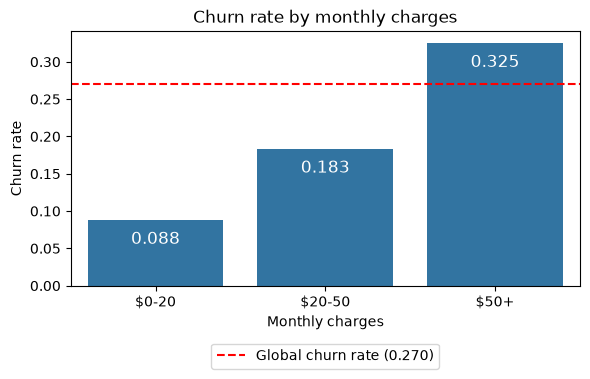

In [43]:
monthlycharges_group = pd.cut(
    df_full_train['monthlycharges'],
    bins=[0, 20, 50, float('inf')],  # (0, 20], (20, 50], (50, inf]
    labels=['$0-20', '$20-50', '$50+'],
)

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=monthlycharges_group, y=df_full_train['churn'], errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.3f', label_type='edge', padding=-20, color='white', fontsize=12)
ax.axhline(global_churn_rate, color='red', linestyle='--', label=f'Global churn rate ({global_churn_rate:.3f})')

plt.title('Churn rate by monthly charges')
plt.xlabel('Monthly charges')
plt.ylabel('Churn rate')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()


**Insight:** Churn rate rises with monthly charges: customers paying $20 or less churn at about 9%, while those paying over $50 churn at about 32%, above the global rate of 27%.


## One-Hot Encoding

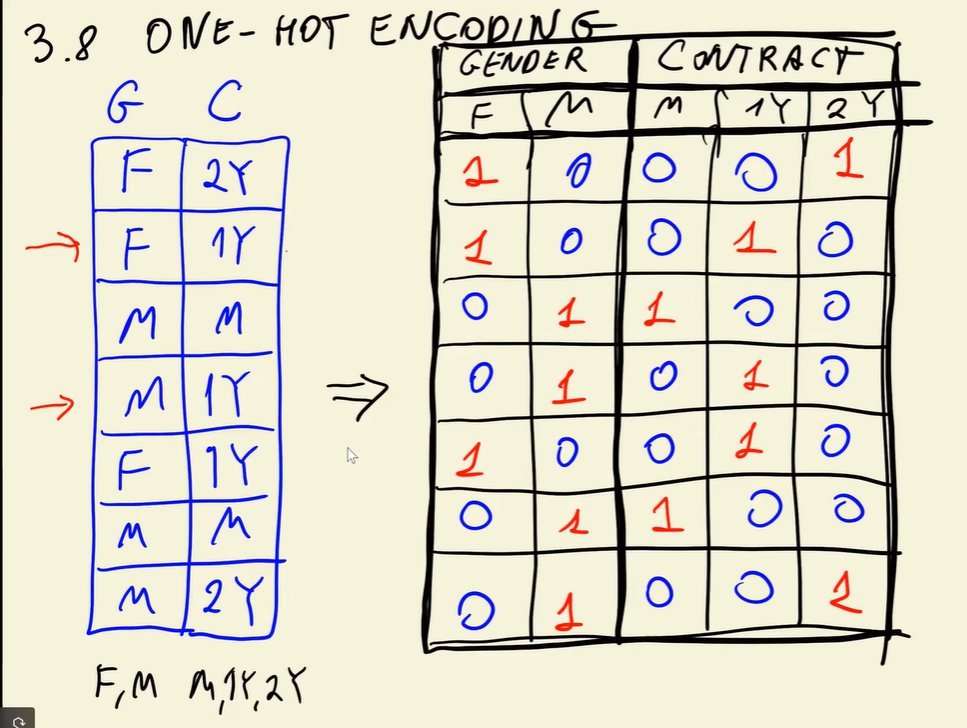

### Example on a subset of data

In [44]:
subset = df_train[['gender', 'contract', 'tenure']].iloc[:100]
subset

,gender,contract,tenure
0,female,two_year,72
1,male,month-to-month,10
2,female,month-to-month,5
3,female,month-to-month,5
4,female,two_year,18
...,...,...,...
95,male,one_year,39
96,female,month-to-month,19
97,male,month-to-month,21
98,male,one_year,43


In [45]:
# Must specify orient='records' because we need to have a list of dicts
dicts = subset.to_dict(orient='records')
dicts

[{'gender': 'female', 'contract': 'two_year', 'tenure': 72},
 {'gender': 'male', 'contract': 'month-to-month', 'tenure': 10},
 {'gender': 'female', 'contract': 'month-to-month', 'tenure': 5},
 {'gender': 'female', 'contract': 'month-to-month', 'tenure': 5},
 {'gender': 'female', 'contract': 'two_year', 'tenure': 18},
 {'gender': 'male', 'contract': 'month-to-month', 'tenure': 4},
 {'gender': 'male', 'contract': 'month-to-month', 'tenure': 1},
 {'gender': 'female', 'contract': 'month-to-month', 'tenure': 1},
 {'gender': 'female', 'contract': 'two_year', 'tenure': 72},
 {'gender': 'female', 'contract': 'month-to-month', 'tenure': 6},
 {'gender': 'female', 'contract': 'two_year', 'tenure': 72},
 {'gender': 'male', 'contract': 'month-to-month', 'tenure': 17},
 {'gender': 'female', 'contract': 'two_year', 'tenure': 66},
 {'gender': 'female', 'contract': 'month-to-month', 'tenure': 2},
 {'gender': 'female', 'contract': 'month-to-month', 'tenure': 4},
 {'gender': 'male', 'contract': 'month-to

Apply one-hot encoding

In [46]:
from sklearn.feature_extraction import DictVectorizer

# sparse=False returns a regular array (easy to read)
# The default sparse=True saves memory on large data
dv = DictVectorizer(sparse=False)

# Step 1: Learn which columns to create (one per category value) from the training data only
# Smart enough to not one-hot encode numeric features
dv.fit(dicts)
print(dv.get_feature_names_out())
    

['contract=month-to-month' 'contract=one_year' 'contract=two_year'
 'gender=female' 'gender=male' 'tenure']


In [47]:
# Step 2: Fills in the 1s and 0s for categorical columns
# Copies numeric columns as they are
dv.transform(dicts)

array([[ 0.,  0.,  1.,  1.,  0., 72.],
       [ 1.,  0.,  0.,  0.,  1., 10.],
       [ 1.,  0.,  0.,  1.,  0.,  5.],
       [ 1.,  0.,  0.,  1.,  0.,  5.],
       [ 0.,  0.,  1.,  1.,  0., 18.],
       [ 1.,  0.,  0.,  0.,  1.,  4.],
       [ 1.,  0.,  0.,  0.,  1.,  1.],
       [ 1.,  0.,  0.,  1.,  0.,  1.],
       [ 0.,  0.,  1.,  1.,  0., 72.],
       [ 1.,  0.,  0.,  1.,  0.,  6.],
       [ 0.,  0.,  1.,  1.,  0., 72.],
       [ 1.,  0.,  0.,  0.,  1., 17.],
       [ 0.,  0.,  1.,  1.,  0., 66.],
       [ 1.,  0.,  0.,  1.,  0.,  2.],
       [ 1.,  0.,  0.,  1.,  0.,  4.],
       [ 1.,  0.,  0.,  0.,  1.,  3.],
       [ 0.,  0.,  1.,  1.,  0., 71.],
       [ 1.,  0.,  0.,  1.,  0., 32.],
       [ 0.,  1.,  0.,  0.,  1., 53.],
       [ 0.,  0.,  1.,  0.,  1., 56.],
       [ 1.,  0.,  0.,  0.,  1., 61.],
       [ 0.,  1.,  0.,  1.,  0., 41.],
       [ 1.,  0.,  0.,  1.,  0.,  1.],
       [ 0.,  0.,  1.,  1.,  0.,  3.],
       [ 1.,  0.,  0.,  0.,  1.,  3.],
       [ 0.,  0.,  1.,  0

### Fit and Transform in one step (training only)

Now, let's apply this to our real datasets, not just a subset

In [48]:
train_dicts = df_train[categorical_features + numerical_features] \
    .to_dict(orient='records')

train_dicts[0]

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'yes',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'yes',
 'onlinebackup': 'yes',
 'deviceprotection': 'yes',
 'techsupport': 'yes',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'two_year',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check',
 'tenure': 72,
 'monthlycharges': 115.5,
 'totalcharges': 8425.15}

In [49]:
dv = DictVectorizer(sparse=False)

# Do the fit and transform in one step
# Only use this for the train set, use transform only for val and test
X_train = dv.fit_transform(train_dicts)
X_train

array([[   0.  ,    0.  ,    1.  , ...,    1.  ,   72.  , 8425.15],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,   10.  , 1021.55],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    5.  ,  413.65],
       ...,
       [   1.  ,    0.  ,    0.  , ...,    1.  ,    2.  ,  190.05],
       [   0.  ,    0.  ,    1.  , ...,    0.  ,   27.  ,  761.95],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    9.  ,  751.65]],
      shape=(4225, 45))

In [50]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

### Transform validation and test sets

In [51]:
val_dicts = df_val[categorical_features + numerical_features] \
    .to_dict(orient='records')

X_val = dv.transform(val_dicts)

X_val.shape

(1409, 45)

In [52]:
test_dicts = df_test[categorical_features + numerical_features] \
    .to_dict(orient='records')

X_test = dv.transform(test_dicts)

X_test.shape

(1409, 45)

## Logistic Regression

### Concepts

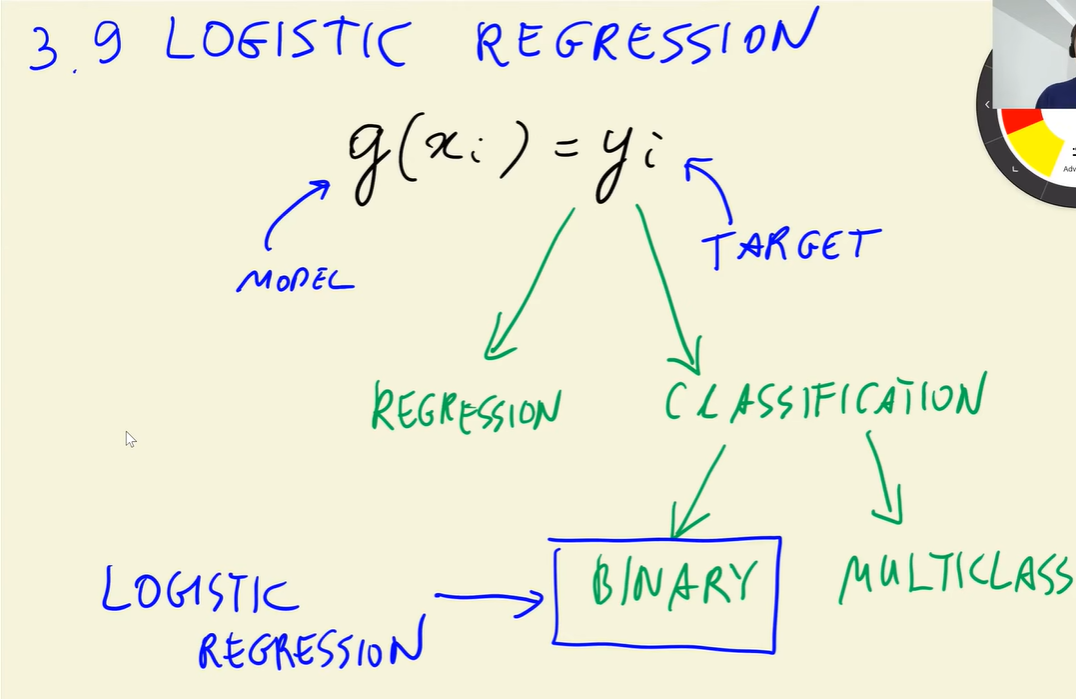

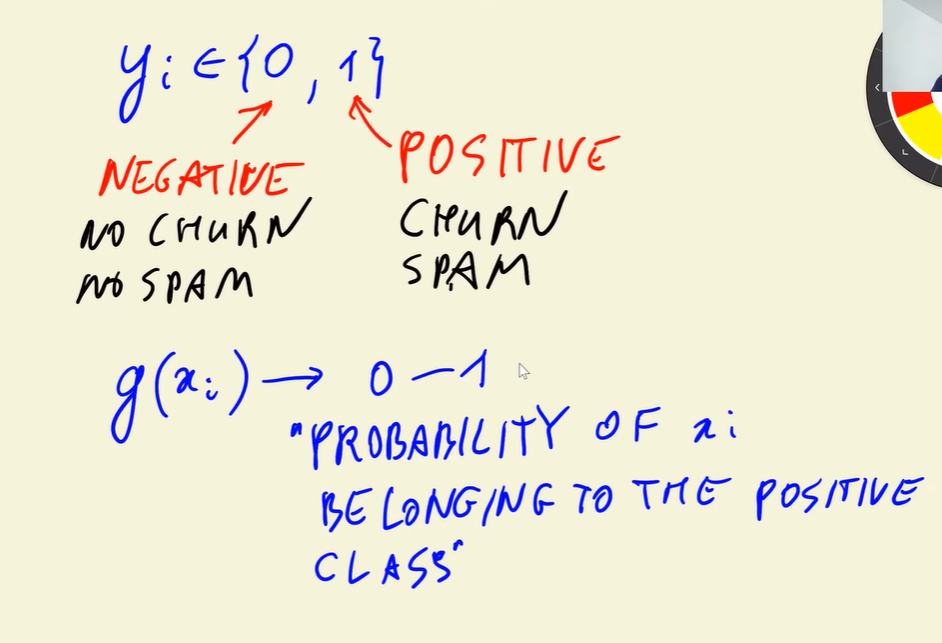

Basically, logistic regression is just a linear regression but wrapped within the **sigmoid function** *(which squeezes the outputs between 0 and 1)*

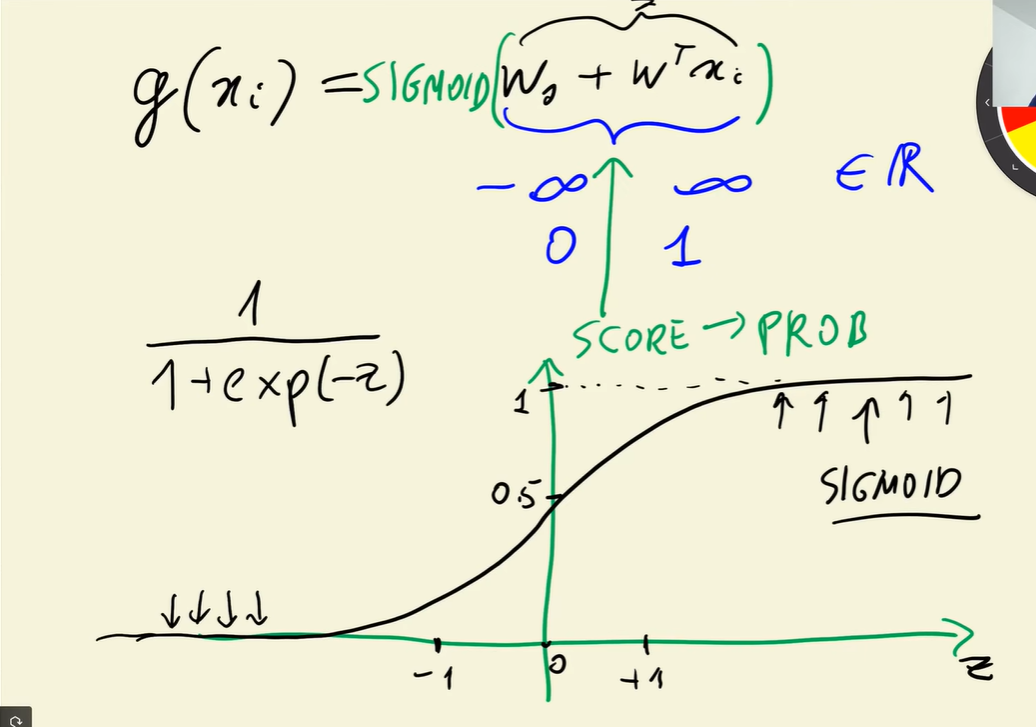

### Implementation

In [53]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [54]:
z = np.linspace(-7, 7, 51)
z

array([-7.  , -6.72, -6.44, -6.16, -5.88, -5.6 , -5.32, -5.04, -4.76,
       -4.48, -4.2 , -3.92, -3.64, -3.36, -3.08, -2.8 , -2.52, -2.24,
       -1.96, -1.68, -1.4 , -1.12, -0.84, -0.56, -0.28,  0.  ,  0.28,
        0.56,  0.84,  1.12,  1.4 ,  1.68,  1.96,  2.24,  2.52,  2.8 ,
        3.08,  3.36,  3.64,  3.92,  4.2 ,  4.48,  4.76,  5.04,  5.32,
        5.6 ,  5.88,  6.16,  6.44,  6.72,  7.  ])

In [55]:
s = sigmoid(z)
s

array([0.00091105, 0.00120508, 0.00159386, 0.0021078 , 0.002787  ,
       0.00368424, 0.00486893, 0.00643211, 0.00849286, 0.01120641,
       0.01477403, 0.01945508, 0.02558079, 0.03356922, 0.04393982,
       0.05732418, 0.07446795, 0.09621554, 0.12346705, 0.15709547,
       0.19781611, 0.24601128, 0.30153478, 0.36354746, 0.43045378,
       0.5       , 0.56954622, 0.63645254, 0.69846522, 0.75398872,
       0.80218389, 0.84290453, 0.87653295, 0.90378446, 0.92553205,
       0.94267582, 0.95606018, 0.96643078, 0.97441921, 0.98054492,
       0.98522597, 0.98879359, 0.99150714, 0.99356789, 0.99513107,
       0.99631576, 0.997213  , 0.9978922 , 0.99840614, 0.99879492,
       0.99908895])

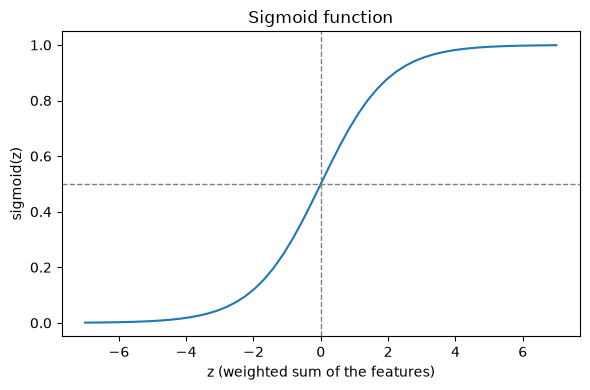

In [56]:
plt.figure(figsize=(6, 4))
sns.lineplot(x=z, y=sigmoid(z))
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1)  # 0.5 = the "undecided" point
plt.axvline(0, color='gray', linestyle='--', linewidth=1)

plt.title('Sigmoid function')
plt.xlabel('z (weighted sum of the features)')
plt.ylabel('sigmoid(z)')
plt.tight_layout()
plt.show()

Write the code logic manually

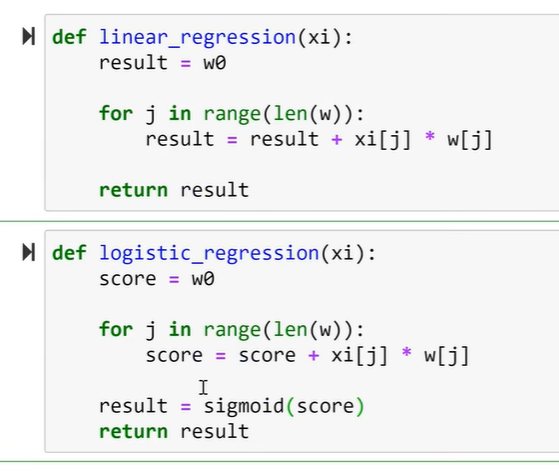

In practice, it's more efficient to just use sklearn for this

## Training Logistic Regression

### Create a model and train it

In [58]:
X_train

array([[   0.  ,    0.  ,    1.  , ...,    1.  ,   72.  , 8425.15],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,   10.  , 1021.55],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    5.  ,  413.65],
       ...,
       [   1.  ,    0.  ,    0.  , ...,    1.  ,    2.  ,  190.05],
       [   0.  ,    0.  ,    1.  , ...,    0.  ,   27.  ,  761.95],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    9.  ,  751.65]],
      shape=(4225, 45))

In [59]:
y_train

0       0
1       0
2       1
3       0
4       0
       ..
4220    0
4221    0
4222    1
4223    0
4224    1
Name: churn, Length: 4225, dtype: int64

In [67]:
from sklearn.linear_model import LogisticRegression

# Create model
model = LogisticRegression(random_state=RANDOM_SEED)

# Train (fit) the model
model.fit(X_train, y_train)

/home/red/ml-zoomcamp-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

In [68]:
# Take a look at the learned bias
model.intercept_[0].round(3)

np.float64(-0.109)

In [69]:
# Take a look at the learned weights
model.coef_[0].round(3)

array([ 0.474, -0.175, -0.407, -0.03 , -0.078,  0.063, -0.089, -0.081,
       -0.034, -0.073, -0.335,  0.316, -0.089,  0.004, -0.258,  0.141,
        0.009,  0.063, -0.089, -0.081,  0.265, -0.089, -0.284, -0.231,
        0.123, -0.166,  0.058, -0.087, -0.032,  0.07 , -0.059,  0.141,
       -0.249,  0.215, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
        0.213, -0.089, -0.232, -0.071,  0.   ])

### Hard vs soft predictions

**Hard predictions** - The actual labels the model predicts (e.g. churn - 1, not churn - 0)

In [70]:
model.predict(X_val)

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

**Soft predictions** - The probabilities the model assigns

In [71]:
model.predict_proba(X_val)

array([[0.99099851, 0.00900149],
       [0.79590966, 0.20409034],
       [0.78827495, 0.21172505],
       ...,
       [0.86364921, 0.13635079],
       [0.20057621, 0.79942379],
       [0.16291404, 0.83708596]], shape=(1409, 2))

`predict_proba()` outputs two columns:

- The left column is the probability for the 0 class (not churn)
- The right column is the probability for the 1 class (churn)

### Set our own threshold

In [72]:
# Take only the 1 class (churn)
y_pred = model.predict_proba(X_val)[:, 1]
y_pred

array([0.00900149, 0.20409034, 0.21172505, ..., 0.13635079, 0.79942379,
       0.83708596], shape=(1409,))

In [74]:
threshold = 0.5

churn_decision = (y_pred >= threshold)
churn_decision

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [75]:
df_val[churn_decision].customerid

3       8433-wxgna
8       3440-jpscl
11      2637-fkfsy
12      7228-omtpn
19      6711-fldfb
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 311, dtype: str

Going back to our original business problem, we have now found the customers to whom we can send promos to hopefully keep them

### Evaluate the model

We can use accuracy to evaluate the performance of our model

***Note:** Not the best metric since earlier we found that the target was imbalanced, better to choose precision, recall, or f1 score. But for the sake of the lesson, just followed here*

In [78]:
churn_decision.astype('int')

(y_val == churn_decision).mean().round(4)

np.float64(0.8034)

In [80]:
df_pred = pd.DataFrame()

df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val
df_pred['correct'] = df_pred.prediction == df_pred.actual

df_pred

,probability,prediction,actual,correct
0,0.009001,0,0,True
1,0.204090,0,0,True
2,0.211725,0,0,True
3,0.542751,1,1,True
4,0.213315,0,0,True
...,...,...,...,...
1404,0.313144,0,0,True
1405,0.039347,0,1,False
1406,0.136351,0,0,True
1407,0.799424,1,1,True


In [82]:
df_pred['correct'].mean().round(4)

np.float64(0.8034)

## Model Interpretation

## Using the Model